# BIOM5350 — In-Class Activity: Coding with AI I

This is the first of two in-class activities. In **Coding with AI II** you will work with an AI agent on CoCalc to plan and run a real analysis. The question for both activities is:

> **Which genes are consistently differentially expressed in dilated cardiomyopathy (DCM) compared with non-failing hearts, across two independent studies?**

The two studies are public microarray datasets in the Gene Expression Omnibus (GEO): **GSE5406** and **GSE42955**. You will analyze each one, then combine the results to find the genes that replicate.

The agent can write the code quickly. It cannot decide for you which samples are comparable, which method fits, or what a correct answer looks like. Today prepares you to make those decisions and to check the agent's work.

Today you will:

1. Review how **microarray** expression data differ from the RNA-seq data you have already analyzed, and what stays the same.
2. Read the **GEO records** for both studies and work out the platform, the sample groups, and what data are available.
3. Write a **framing statement** for the analysis, before using any AI tool.
4. Draft a structured **brief** for an AI agent.
5. Use AI to **explain, comment and rewrite** code, and verify that the rewrite gives the same result.
6. Set up the **GitHub repository** you will use for Coding with AI II.

## How to use this notebook

Work through the parts in order. This notebook uses the **R** kernel.

Each part says whether AI use is **not allowed** or **required**. Parts 1 to 4 are your own thinking; that is the point of them. Part 5 uses the AI assistant in CoCalc.

Cells labelled **ANSWER** are plain-text cells for your responses. Click into one, type your answer, and move on. Run code cells with Shift+Enter, and only where a code cell is provided.

In Part 6, terminal commands are shown in boxes with `$>` standing for the terminal prompt. Type what follows `$>`, not the `$>` itself.

### Deliverables

| Part | Deliverable | AI use |
|---|---|---|
| 1. Array refresher | Answers to Q1–Q3 | Not allowed |
| 2. Reading a GEO record | Answers to Q4–Q7 | Not allowed |
| 3. Framing the problem | Framing statement and first decisions (Q8–Q10) | Not allowed |
| 4. Drafting the brief | A draft brief you will use in Coding with AI II (Q11) | Not allowed |
| 5. Using AI to understand code | Commented code, a tidyverse rewrite, a passing equality check, answers to Q12–Q15, and the saved chat | Required |
| 6. Repository setup | A public GitHub repository with the starting layout, containing this notebook and your Part 5 chat (Q16) | Your choice |

## Part 1 — Refresher: gene expression by microarray

**AI use: not allowed.**

Earlier in the course you analyzed RNA-seq data. Both datasets in this activity are from Affymetrix microarrays. The question is the same (which genes differ between groups?) and much of the workflow carries over, but the measurements and the first processing steps are different.

### 1a. What an array measures

A microarray carries short DNA **probes** fixed at known positions. Labeled RNA from a sample binds to matching probes, and a scanner records the fluorescence **intensity** at each position. Several probes that target the same transcript form a **probe set**, and each probe set gets one expression value per sample.

- The raw output of one Affymetrix array is a **CEL file**: the intensity of every probe on that array. CEL files are binary, so you cannot read them with `head` or `less`.
- The set of probes is fixed by the array design, called the **platform**. Different platforms have different probe sets with different IDs.
- A probe set ID such as `209957_s_at` means nothing by itself. You need the platform's **annotation** to know which gene it targets. One gene can have several probe sets, and some probe sets map to no gene, or to more than one.

**It is important to know which platform a dataset used.** The annotation must match the platform exactly. Guessing here produces results that look fine and are wrong.

### 1b. Arrays compared with RNA-seq

| | RNA-seq | Microarray |
|---|---|---|
| What is measured | Reads counted per gene | Fluorescence intensity per probe |
| Raw file | FASTQ | CEL |
| From raw file to one value per feature | Alignment or pseudo-alignment, then counting reads | Background correction, then summarizing the probes in each probe set |
| Normalization between samples | Size factors that adjust for sequencing depth and composition. DESeq2 estimates them inside `DESeq()` and uses them in the model; the counts themselves are not changed | Quantile normalization, done as part of RMA before any modeling; the values themselves are changed |
| Scale of the values | Integer counts | Continuous, usually log2 intensity |
| Typical model for differential expression | Negative binomial (for example DESeq2) | Linear model with moderated t-statistics (limma) |
| What a "feature" is | A gene or transcript from an annotation | A probe set fixed by the array design |
| **Shared by both** | Quality control, the need to normalize, experimental design, multiple-testing correction, annotation, interpretation | |

### 1c. The workflow

The figure below, from Slonim and Yanai (2009), shows the overall flow of a microarray study. The green and purple steps are the ones you do on a computer.

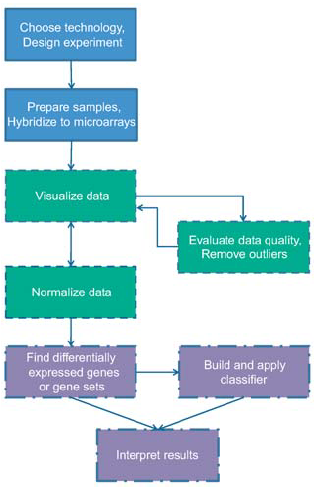

*Figure 1 of Slonim and Yanai (2009), PLoS Computational Biology.*

### 1d. Normalization with RMA

Raw intensities differ from array to array for technical reasons: how much RNA was loaded, how well it labeled, how the scanner behaved. Those differences have to be removed before arrays can be compared.

The standard method for Affymetrix arrays is the **Robust Multi-array Average (RMA)**. It does three things:

1. **Background correction** of the probe intensities.
2. **Quantile normalization**, which forces every array to have the same distribution of intensities.
3. **Summarization** of the probes in each probe set into one value, reported on the **log2 scale**.

Two consequences matter for this analysis:

- RMA is computed **across a set of arrays together**. Which arrays were in that set affects every value.
- Values are log2. A difference of 1 between groups is a two-fold change; a difference of 2 is four-fold.

The two plots below show the same eight arrays (an example from mouse liver and spleen) before and after RMA. Each box is the distribution of expression values on one array.

**Before normalization**

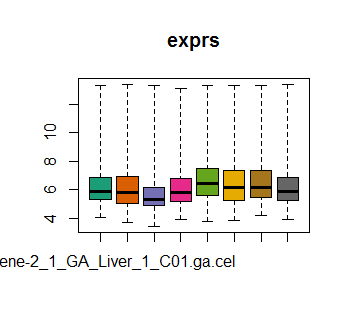

**After RMA**

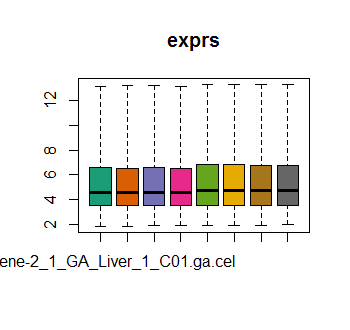

### 1e. Testing for differential expression

For each probe set we ask whether expression differs between groups:

- **H0:** the condition has no effect on expression (β = 0)
- **H1:** the condition has an effect on expression (β ≠ 0)

Here β is the difference in mean log2 expression between groups, which is the **log2 fold change**.

Array studies often have few samples per group, which makes each gene's variance estimate noisy. The **limma** package handles this with **moderated t-statistics**: it borrows information across all genes to stabilize each gene's variance (an empirical Bayes approach). The functions you will see are `lmFit()`, `eBayes()` and `topTable()`.

Because thousands of probe sets are tested at once, **multiple-testing issues apply**. A nominal p-value below 0.05 is not evidence by itself. limma reports an adjusted p-value (`adj.P.Val`), by default using the Benjamini–Hochberg method, which controls the false discovery rate.

### Questions

**Q1.** A probe set has a log2 fold change of −1.5 for DCM compared with control. In which group is expression higher, and by roughly what factor?

**Q2.** Compare the two boxplots in section 1d. What changed after normalization? Why does this have to happen before you compare groups?

**Q3.** Suppose two studies used different array platforms. Why can you not combine their results by matching probe set IDs? What would you match on instead, and what complication does section 1a warn you about?

## Part 2 — Reading a GEO record

**AI use: not allowed.** Read the records yourself. In Coding with AI II you will compare what you found with what the agent reports.

[GEO](https://www.ncbi.nlm.nih.gov/geo/) organizes data with three kinds of accession:

| Accession | What it is | Example |
|---|---|---|
| **GSE** (series) | One study: a set of samples with a description and usually a citation | GSE5406 |
| **GSM** (sample) | One sample, with its own description and data | GSM123518 |
| **GPL** (platform) | The array design, with the annotation table that maps probe set IDs to genes | GPL96 |

A series record also tells you what data you can get:

- The **series matrix** file contains the expression values the submitter uploaded, already processed, together with the sample descriptions.
- **Supplementary files** may include the raw CEL files, usually as a single `_RAW.tar` archive.

Open both records and read them carefully, including a few individual sample (GSM) pages:

- [GSE5406](https://www.ncbi.nlm.nih.gov/geo/query/acc.cgi?acc=GSE5406)
- [GSE42955](https://www.ncbi.nlm.nih.gov/geo/query/acc.cgi?acc=GSE42955)

**Do not download any data yet.** That happens in Coding with AI II, after you have an approved plan.

### Questions

**Q4.** Record the following for each study.

**Q5.** For each study, which groups belong in a comparison of DCM with non-failing hearts, and which samples would you exclude? How many samples per group remain in each study?

**Q6.** GSE5406 provides no raw files. Read how the submitter describes the processing, and note which samples were processed together. Name one thing this means you cannot check or redo yourself.

**Q7.** These are human tissue samples. Is it appropriate to use these two datasets with an AI tool that runs on a vendor's servers? What property of the data makes it acceptable or not? Give one example of a dataset where your answer would be different.

## Part 3 — Framing the problem

**AI use: not allowed.**

From lecture: *framing is the problem solving, and coding is writing it down.* An agent will make every framing decision for you if you leave it open, and it will not always tell you that it did.

The table below lists the decision areas that an analysis plan for this project has to cover. In Coding with AI II you will keep a **decision log** with one entry per area: what you decided, why, and whether you or the agent raised it. For now, read the guiding questions and notice which ones you can already answer.

| # | Decision area | Guiding questions |
|---|---|---|
| 1 | The brief | What is the goal? What may the agent do before you approve the plan? What must it deliver? |
| 2 | The data | Which accessions and platforms? How many samples does GEO report? |
| 3 | The comparison | Which groups are compared? Which samples are in and out of each study, and why? |
| 4 | Metadata checks | Are the group labels unambiguous? Do GEO and the paper agree? |
| 5 | Expression input | Raw files you process yourself, or the submitter's processed values? How do you confirm the scale? |
| 6 | Quality control | Which diagnostics will you look at? What is the rule for excluding a sample, decided in advance? |
| 7 | Probes to genes | Which annotation? What happens when several probe sets map to one gene, or none? |
| 8 | The model | Which method? Any covariates? Which direction is the contrast? What is reported for each gene? |
| 9 | Combining studies | What does "consistently differentially expressed" mean, stated precisely enough to compute? |
| 10 | Checks | What does a correct result look like at each step? |
| 11 | Deliverables | Which notebooks, figures and tables? How are package versions recorded? |
| 12 | Limitations | What can this design not tell you? |

### Questions

**Q8. Framing statement.** In one paragraph, state the question, the data, the comparison, and what the final product of the analysis should be. Write it so that a classmate could tell whether the finished analysis delivered what you described.

**Q9. First decisions.** For each of the three areas below, write your current decision and one sentence of reasoning. If you cannot decide yet, write what you would need to learn first.

- Area 5, expression input
- Area 8, what counts as "differentially expressed"
- Area 9, what counts as "consistent" across the two studies

**Q10. Knowing what right looks like.** List at least three checks you could make on the finished analysis that do not depend on trusting the AI. At least one should be a count you can verify against GEO, and at least one should be a biological expectation, such as a gene whose behavior in heart failure is well established. Say where you would look that up.

## Part 4 — Drafting the brief

**AI use: not allowed.** Write this yourself. You will give it to the agent in Coding with AI II.

A prompt is a specification: whatever you leave out, the model fills in with a guess. From lecture, a good prompt has five parts.

| Part | What it contains |
|---|---|
| **Context** | What the project is, what the data look like, what you have already done |
| **Task** | The one thing you want, stated specifically |
| **Constraints** | Language, libraries, what must not change, what to avoid |
| **Output format** | A notebook, a table, a document, and how long |
| **Examples** | A sample of the input, or of the result you expect |

In Coding with AI II you will start by asking the agent for a **plan**, not for code. For that first message, the brief should also do three things:

- **Set a boundary.** Say what the agent may do before you approve the plan (for example, read GEO records) and what it may not (for example, download expression data or run analyses).
- **Ask to be interviewed.** Tell the agent to question you on the details of the analysis before it writes the plan.
- **Name the conventions.** State the language and style you want for any code, including that it must be commented and readable by a person.

There is no magic wording. The aim is to say what you actually want.

### Question

**Q11. Draft brief.** Write the first message you will send to the agent. Before you finish, check that it:

- states the scientific goal and names both accessions
- asks for a plan first, and asks the agent to interview you
- says what the agent may and may not do before you approve the plan
- lists the deliverables you expect at the end
- states the coding conventions you want

## Part 5 — Using AI to understand code

**AI use: required.** Use the AI assistant in CoCalc.

In Coding with AI II the agent will produce code faster than you can write it. The code arrives whether or not you understand it, so understanding has to be something you set out to build. This part practices the habits from lecture on a small example:

- predict the output before you run the code
- ask the AI to explain the code, then check the explanation against the code
- have it add comments and rewrite the code in a style you prefer
- **verify that the rewrite gives exactly the same result**

The last habit matters most. Rewriting code for style must never change the answer, and you confirm that by running a check, not by asking the AI.

### 5a. The example

The cell below creates two small tables. `results` is the kind of table limma produces: one row per probe set, with a log2 fold change and p-values. `annot` maps probe set IDs to gene symbols. **The values are invented for this exercise.**

Run the cell.

In [ ]:
# A small, made-up differential expression result: one row per probe set.
results <- data.frame(
  probe     = c("1001_at", "1002_s_at", "1003_at", "1004_at", "1005_at",
                "1006_x_at", "1007_at", "1008_at", "1009_at", "1010_at"),
  logFC     = c(2.10, 1.40, -1.35, -1.39, 1.01, 0.30, 0.90, -0.80, 0.02, -0.70),
  P.Value   = c(2e-9, 4e-6, 6e-6, 1e-12, 9e-10, 0.08, 2e-5, 4e-5, 0.90, 5e-4),
  adj.P.Val = c(1e-6, 3e-4, 4e-4, 2e-9, 8e-7, 0.21, 0.001, 0.002, 0.95, 0.012),
  stringsAsFactors = FALSE
)

# A small, made-up annotation table: probe set ID to gene symbol.
# Note that 1008_at is missing from this table, and 1007_at has an empty symbol.
annot <- data.frame(
  probe_id = c("1001_at", "1002_s_at", "1003_at", "1004_at", "1005_at",
               "1006_x_at", "1007_at", "1009_at", "1010_at"),
  symbol   = c("NPPA", "NPPA", "MYH6", "SERPINA3", "FRZB",
               "FRZB", "", "GAPDH", "CORIN"),
  stringsAsFactors = FALSE
)

results
annot

### 5b. Predict, then run

The next cell is written in **base R**. It joins the two tables and reduces them to one row per gene. Read it before you run it.

**Q12. Predict.** Without running the code, write down how many rows you expect in each of `merged` (after the first assignment), `annotated`, `sig` and `best`. Then run the cell and record the actual numbers. If any prediction was wrong, say what you had misread.

In [ ]:
colnames(annot)[1] <- "probe"
merged <- merge(results, annot, by = "probe", all.x = TRUE)
annotated <- merged[!is.na(merged$symbol) & merged$symbol != "", ]
sig <- annotated[annotated$adj.P.Val < 0.05, ]
sig$direction <- ifelse(sig$logFC > 0, "up", "down")
sig <- sig[order(sig$adj.P.Val), ]
best <- sig[!duplicated(sig$symbol), ]
rownames(best) <- NULL

nrow(merged); nrow(annotated); nrow(sig); nrow(best)
best
table(best$direction)

### 5c. Ask the AI to explain it

Open the AI assistant and ask it to explain the base R code above. Follow the lecture's advice:

- **Paste, don't describe.** Give it the actual code, and the actual output of `results` and `annot`.
- **Say what you already know**, so the explanation starts at your level.
- Ask it to explain **why** each step is there, not only what the function does.

Then check its explanation against the code. An explanation is generated text too, and it can be wrong.

**Q13.** In your own words, explain what each of these three pieces does and why it is needed:

- `all.x = TRUE` in the call to `merge()`
- the condition `!is.na(merged$symbol) & merged$symbol != ""`
- `order()` followed by `!duplicated(sig$symbol)`

Then describe one claim in the AI's explanation that you checked by running something yourself, and what you ran.

### 5d. Ask the AI to add comments

Ask the AI to add comments to the base R code. Read every comment. Delete or fix any comment that is wrong, that only restates the function name, or that you could not defend if asked. A good comment says why a step is there.

Paste the commented base R code into the cell below and run it. It must still produce the same `best` table.

In [ ]:
# Paste your commented base R version here.

### 5e. Ask the AI to rewrite it with the tidyverse

Ask the AI to rewrite the same steps using tidyverse functions and the pipe, with comments. Tell it two things:

- the final table must be called **`best_tidy`**
- it must start from `results` and `annot` as they are now, and must not change `best`

Paste the result into the cell below and run it.

In [ ]:
# Paste your commented tidyverse version here. It must create best_tidy.

### 5f. Verify that the two versions agree

Run the cell below. It compares the contents of the two tables. `as.data.frame()` is there because tidyverse functions return a tibble, and you want to compare the values, not the type of table.

You are aiming for a single `TRUE`.

In [ ]:
all.equal(as.data.frame(best_tidy), best, check.attributes = FALSE)

**Q14.** Did the check return `TRUE` the first time? If not, paste the message it gave, say what differed between the two tables, and describe how you got them to agree. If it did pass, name one way a rewrite like this could have silently changed the result.

**Q15.** The code keeps, for each gene, the probe set with the smallest adjusted p-value. Ask the AI for two other rules people use when several probe sets map to one gene. Which rule would you choose for this project, and could the choice change which genes appear in your final list? This is decision area 7; you will use your answer in Coding with AI II.

### 5g. Save the chat

Your conversation with the AI is part of your record of how the work was done. On CoCalc the chat is stored as a `.chat` file in your project. Keep it; you will add it to your repository in Part 6.

Before you share a chat file, look through it. It can contain account identifiers, file paths, and anything you pasted.

## Part 6 — Set up your repository

You created GitHub repositories in the git and GitHub module. Create a new one for this project now, so that Coding with AI II can start with the analysis.

### 6a. Create the repository on GitHub and clone it

1. On github.com click the **+** (top right) ▸ **New repository**.
2. Repository name: `biom5350-dcm-consensus`
3. **Public**, so the TAs can verify your work.
4. Check **Add a README file**, then click **Create repository**.

In the terminal, clone it into your `~/biom5350` folder using the SSH URL from **Code ▸ SSH**, and move into it:

```
$> cd ~/biom5350
$> git clone git@github.com:<your-username>/biom5350-dcm-consensus.git
$> cd biom5350-dcm-consensus
```

### 6b. Create the starting layout

Build this layout inside the repository. You know the commands (`mkdir -p`, `touch`, and the CoCalc editor for the text files).

```
biom5350-dcm-consensus/
├── README.md          one or two sentences on what the project is
├── .gitignore         must contain the line  data/raw/
├── worksheets/        this notebook, and the Coding with AI II worksheet
├── chat/              exported chat files
├── plan/              the analysis plan (written in Coding with AI II)
├── notebooks/         analysis notebooks (written in Coding with AI II)
├── results/
│   ├── figures/
│   └── tables/
└── data/
    └── raw/           downloaded data; never committed
```

Git does not track empty folders. Put an empty placeholder file named `.gitkeep` in each folder that has nothing in it yet (`plan/`, `notebooks/`, `results/figures/`, `results/tables/`, `data/raw/`).

`data/raw/` is listed in `.gitignore` because downloaded data does not belong in the repository: it is large, and anyone can fetch it again from GEO using the accession.

### 6c. Add today's work, commit and push

1. Save this notebook, then copy it into `worksheets/` and copy your Part 5 chat file into `chat/`.
2. Check `git status`, stage the new files, commit with a message that describes what you added, and push.

Run the verification cell. You should see your commits, `origin` pointing at your repository on github.com, and the folders listed above.

In [ ]:
# Verification: commit history, remote, and tracked files
out <- system("cd ~/biom5350/biom5350-dcm-consensus && git log --oneline && git remote -v && git ls-files", intern = TRUE)
cat(out, sep = "\n")

**Q16.** Paste the URL of your repository.

## Before Coding with AI II

Check that you have:

* Answered Q1–Q16
* Written a framing statement (Q8) and a draft brief (Q11)
* A commented base R version, a tidyverse version, and a `TRUE` from the equality check
* Saved the Part 5 chat
* Pushed your repository with the starting layout, this notebook and the chat

Bring your framing statement, your draft brief and your answer to Q15. You will use all three at the start of Coding with AI II.

## Further reading

- Slonim DK, Yanai I (2009). Getting started in gene expression microarray analysis. *PLoS Computational Biology* 5(10): e1000543.
- Irizarry RA et al. (2003). Exploration, normalization, and summaries of high density oligonucleotide array probe level data. *Biostatistics* 4(2): 249–264.
- Smyth GK (2004). Linear models and empirical Bayes methods for assessing differential expression in microarray experiments. *Statistical Applications in Genetics and Molecular Biology* 3: Article 3.